<a href="https://colab.research.google.com/github/guyen5/Capstone/blob/main/4_Replication_Run_Paper_like_PTOO.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook 4: Replication Run (paper-like PTO)

This is the updated replication run. It follows Notebook 4, with one change decided by diagnostic D2: **plain PTO is now the paper-like model**, a separate unpenalized regression for each ETF fitted on the month-end rows of the 9-month fit period. Of all variants tested in D1 and D2, it is the simplest that reproduces the paper's PTO turnover, using two details the paper does not state.

Three strategies run through the same optimizer, for every λ, on both universes, over the 81 test months:

| Strategy | Expected returns | Role |
|---|---|---|
| Paper-like PTO | Per-ETF least-squares forecasts, about 8 month-end rows each | The paper's plain PTO, used for H1 |
| Pooled PTO | One ridge model for all ETFs on daily rows, penalty 0.1 | A sensible second baseline for the extension |
| Classic Markowitz | Mean daily return over the last 126 trading days | The paper's MVO baseline |

The four pass criteria from the Replication Spec are checked in section 8, with paper-like PTO as plain PTO. Section 5 also checks the forecasts against the paper's Figure 1, which shows PTO forecasts staying close to realized returns on average.

**Work package:** WBS 3.4 (Replication run), updated after diagnostics D1 and D2

**Inputs:** Daily Features, Daily Training Windows and Covariances from Notebook 3, Monthly Data from Notebook 2, Daily Prices from Notebook 1

**Outputs** (Google Drive, `Capstone/data`; separate names, so Notebook 4's own outputs are kept):

| File | Folder | Contents |
|---|---|---|
| Paper-like PTO Forecasts.parquet | processed | Each ETF's paper-like forecast at each decision date |
| Replication Months (paper-like).parquet | processed | Monthly gross and net return, fee and turnover of all three strategies |
| Replication Results (paper-like).csv | reports | Return, volatility, Sharpe ratio, drawdown and turnover of each run, next to the paper |
| Replication Checks (paper-like).csv | reports | Results of all checks, including the four pass criteria |

## 1. Setup

Connects Google Drive, where all data files are stored, and loads the project code from the GitHub repository. Run this cell first in every new Colab session.

**GitHub token (only if the repository is private).** The repository is public, so no token is needed. If it is ever made private, create a read-only fine-grained token on GitHub for the Capstone repository and add it in Colab's Secrets panel (key icon) as `GITHUB_TOKEN`, with notebook access turned on.

In [1]:
# Connect Google Drive. All data files are read from and saved to
# MyDrive/Capstone/data.
from google.colab import drive, userdata
drive.mount("/content/drive")

import os
import shutil
import subprocess
import sys

REPO = "guyen5/Capstone"
REPO_DIR = "/content/Capstone"

# The repository is public, so no login is needed. A GitHub token stored as
# the Colab secret GITHUB_TOKEN is used only if one exists, in case the
# repository is ever made private.
try:
    token = userdata.get("GITHUB_TOKEN")
except Exception:
    token = None
url = f"https://{token}@github.com/{REPO}.git" if token else f"https://github.com/{REPO}.git"

# Download a fresh copy of the code on every run, so the notebook always
# uses the latest version on GitHub. Stop if the download fails rather than
# run on an old copy.
shutil.rmtree(REPO_DIR + "_new", ignore_errors=True)
result = subprocess.run(["git", "clone", "--quiet", url, REPO_DIR + "_new"],
                        capture_output=True, text=True)
if result.returncode != 0:
    raise RuntimeError("Could not download the code from GitHub. Check that the repository "
                       "guyen5/Capstone is public, or add a GitHub token as the Colab secret GITHUB_TOKEN.")
shutil.rmtree(REPO_DIR, ignore_errors=True)
os.rename(REPO_DIR + "_new", REPO_DIR)
print(subprocess.run(["git", "-C", REPO_DIR, "log", "-1", "--date=format:%Y-%m-%d %H:%M",
                      "--format=Code version: %h, %s (%cd)"], capture_output=True, text=True).stdout)

# Install the pinned library versions listed in requirements.txt.
%pip install --quiet -r {REPO_DIR}/requirements.txt

# Make the project modules importable with "from src import ...".
if REPO_DIR not in sys.path:
    sys.path.insert(0, REPO_DIR)

Mounted at /content/drive
Code version: 9ced6a2, Note that the repository is public in the setup cells (2026-10-26 23:59)



In [2]:
import importlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import config, cleaning, windows, variables, backtest, forecast

for module in (config, cleaning, windows, variables, backtest, forecast):
    importlib.reload(module)

DIRS = config.data_dirs()
pd.set_option("display.width", 170)
checks = []

## 2. Load the inputs

The same files as Notebook 4. Only the paper's 9+3 window is used.

In [3]:
proc = DIRS["processed"]
clean = cleaning.load_clean(proc)
panel = pd.read_parquet(proc / config.FILES["monthly"])
daily_table = pd.read_parquet(proc / config.FILES["daily_table"])
all_windows = pd.read_parquet(proc / config.FILES["daily_windows"])
cov_table = pd.read_parquet(proc / config.FILES["covariances"])

calendar = all_windows[all_windows["window"] == "9+3"].reset_index(drop=True)
universes = ("ETF_A", "ETF_B")
returns = {u: backtest.holding_returns(panel, u) for u in universes}
cov_sample = {u: backtest.covariance_lookup(cov_table, u, "sample") for u in universes}
hist_mu = {u: backtest.historical_means(clean, returns[u].index, u) for u in universes}
assert (pd.DatetimeIndex(calendar["decision_date"]) == returns["ETF_A"].index).all()
print(f"{len(calendar)} decision dates, {calendar['month'].iloc[0]} to {calendar['month'].iloc[-1]}")

81 decision dates, 2020-01 to 2026-09


## 3. Forecasts

**Paper-like PTO.** At each decision date and for each ETF, an ordinary least-squares regression of the 21-day forward return on that ETF's seven features plus an intercept, fitted on the month-end rows of the 9-month fit period (rows whose targets are known before the validation slice starts, so about 8 rows for 8 coefficients). Nothing is tuned, so the validation slice is not used. With as many coefficients as rows the fit is close to exact, and the forecasts are far more spread out than real returns. That is what makes the portfolio jump.

**Pooled PTO.** Notebook 4's least-shrunk model: one ridge regression for all ETFs on about 1,800 daily rows, penalty 0.1.

In [4]:
def paper_like_forecasts(universe):
    tickers = backtest.tickers_of(universe)
    rows = []
    for _, step in calendar.iterrows():
        fit, val, test = windows.daily_rows_for(daily_table, step, universe)
        fit = fit[fit["month_end"]]
        for t in tickers:
            tr = fit[fit["ticker"] == t]
            x = np.column_stack([np.ones(len(tr)), tr[config.FEATURES].to_numpy(float)])
            beta, *_ = np.linalg.lstsq(x, tr["fwd_return"].to_numpy(float), rcond=None)
            xt = test[test["ticker"] == t][config.FEATURES].to_numpy(float)[0]
            rows.append({"date": step["decision_date"], "month": step["month"], "universe": universe,
                         "ticker": t, "forecast": float(beta[0] + xt @ beta[1:]), "rows": len(tr)})
    return pd.DataFrame(rows)

fc_paper = pd.concat([paper_like_forecasts(u) for u in universes], ignore_index=True)
fc_pooled = pd.concat([forecast.build_forecasts(daily_table, calendar, u, backtest.tickers_of(u),
                                                alphas=[config.PTO_ALPHA_GRID[0]]) for u in universes],
                      ignore_index=True)
print(f"Paper-like: {len(fc_paper):,} forecasts, {fc_paper['rows'].median():.0f} rows per fit (median)")
print(f"Pooled:     {len(fc_pooled):,} forecasts, "
      f"{(fc_pooled['fit_rows'] + fc_pooled['validation_rows']).median():.0f} rows per fit (median)")

Paper-like: 1,458 forecasts, 8 rows per fit (median)
Pooled:     1,458 forecasts, 2290 rows per fit (median)


## 4. Checks on the forecasts

Confirms both sets are complete and finite, that every training target is known before its decision date, and that three random paper-like fits give the same forecasts when refit with scikit-learn's `LinearRegression`.

In [5]:
from sklearn.linear_model import LinearRegression

rows = []
def add(name, ok, detail):
    rows.append({"check": name, "status": "PASS" if ok else "FAIL", "detail": detail, "table": "Forecasts"})

for name, f in (("paper-like", fc_paper), ("pooled", fc_pooled)):
    n = sum(len(calendar) * len(backtest.tickers_of(u)) for u in universes)
    add(f"{name} complete", len(f) == n and np.isfinite(f["forecast"]).all(), f"{len(f):,} finite forecasts")

label = daily_table.drop_duplicates("date").set_index("date")["label_date"]
ok = all(label.loc[s["train_start"]:s["fit_end"]].max() < s["validation_start"] for _, s in calendar.iterrows())
add("no look-ahead", ok, "every paper-like training target is known before the validation slice starts")

rng = np.random.default_rng(0)
worst = 0.0
for i in rng.choice(len(calendar), 3, replace=False):
    step = calendar.iloc[int(i)]
    fit, val, test = windows.daily_rows_for(daily_table, step, "ETF_A")
    fit = fit[fit["month_end"]]
    for t in config.ETF_A:
        tr = fit[fit["ticker"] == t]
        sk = LinearRegression().fit(tr[config.FEATURES].to_numpy(float), tr["fwd_return"].to_numpy(float))
        pred = sk.predict(test[test["ticker"] == t][config.FEATURES].to_numpy(float))[0]
        ours = fc_paper[(fc_paper["date"] == step["decision_date"]) & (fc_paper["ticker"] == t)
                        & (fc_paper["universe"] == "ETF_A")]["forecast"].iloc[0]
        worst = max(worst, abs(pred - ours))
add("matches scikit-learn", worst < 1e-6, f"3 random months x 8 ETFs refit, largest difference {worst:.1e}")

fc_checks = pd.DataFrame(rows)
print(fc_checks.drop(columns="table").to_string(index=False))
checks.append(fc_checks)
if (fc_checks["status"] == "FAIL").any():
    raise RuntimeError("A forecast check failed.")

               check status                                                                       detail
 paper-like complete   PASS                                                       1,458 finite forecasts
     pooled complete   PASS                                                       1,458 finite forecasts
       no look-ahead   PASS every paper-like training target is known before the validation slice starts
matches scikit-learn   PASS                   3 random months x 8 ETFs refit, largest difference 3.4e-12


## 5. How the forecasts compare, and the Figure 1 check

| Measure | Meaning |
|---|---|
| Spread ratio | Cross-ETF spread of forecasts divided by that of realized returns. 1 means as spread out as reality |
| Mean IC | Average monthly rank correlation between forecasts and realized returns. 0 means no ranking skill |
| Out-of-sample R² | 1 minus squared forecast error relative to a forecast of zero |
| Top pick beats average | Share of months in which the top-forecast ETF beat the universe average. 0.5 is chance |

The chart is the paper's Figure 1 view: the average forecast across ETFs against the average realized return each month. The paper's PTO line stays close to the realized line. A paper-like model that matches the paper's trading but not this picture would mean the paper's forecasts were inflated in their differences between ETFs rather than in their average.

                           oos_r2  mean_ic  ic_t_stat  top_pick_beats_average  spread_ratio
model          universe                                                                    
Paper-like PTO ETF_A     -825.166    0.076      1.899                   0.519        23.259
               ETF_B    -3495.091    0.006      0.159                   0.494        30.084
Pooled PTO     ETF_A       -0.262    0.120      2.130                   0.519         0.532
               ETF_B       -0.419   -0.026     -0.480                   0.432         0.507


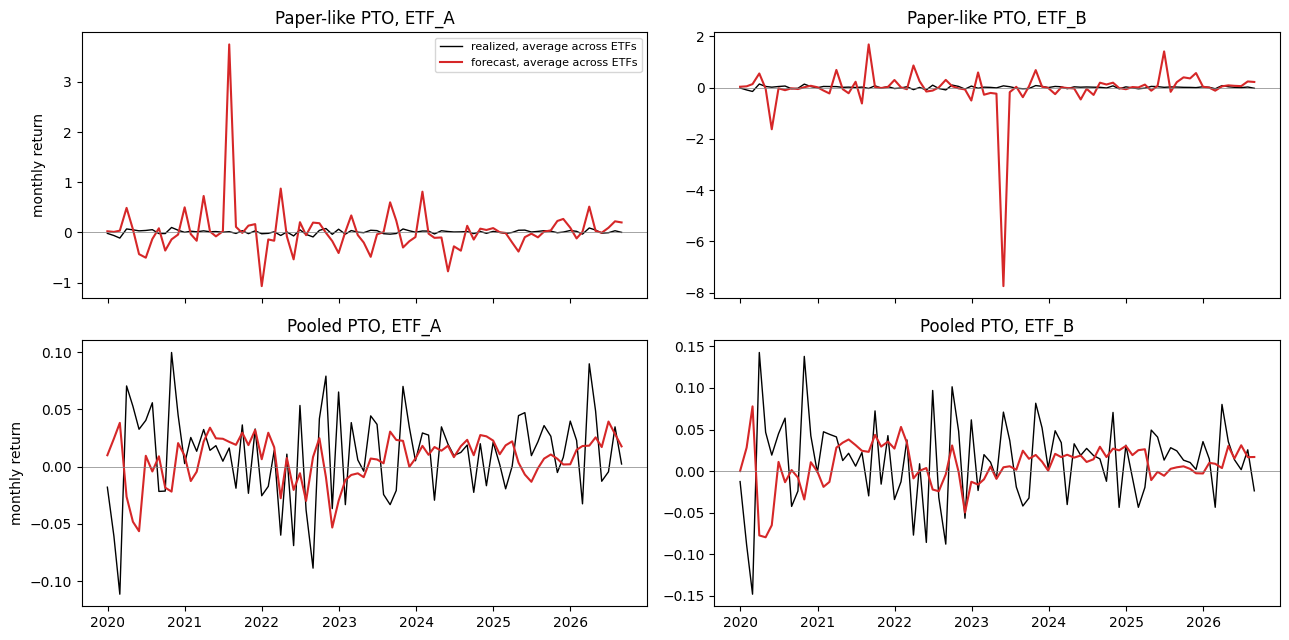


Paper-like PTO, typical size of the average forecast vs the spread across ETFs (median over months)
          |average forecast|  spread across ETFs
universe                                        
ETF_A                  0.133               0.362
ETF_B                  0.113               0.416


In [6]:
q = pd.concat([forecast.forecast_quality(fc_paper, panel).assign(model="Paper-like PTO"),
               forecast.forecast_quality(fc_pooled, panel).assign(model="Pooled PTO")])
print(q.reset_index().set_index(["model", "universe"]).round(3).to_string())

real = panel[["date", "universe", "ticker", "next_return"]]
fig, axes = plt.subplots(2, 2, figsize=(13, 6.5), sharex=True)
for col, u in enumerate(universes):
    for row, (name, f) in enumerate((("Paper-like PTO", fc_paper), ("Pooled PTO", fc_pooled))):
        ax = axes[row, col]
        g = f[f["universe"] == u].merge(real, on=["date", "universe", "ticker"]).groupby("date")[["forecast", "next_return"]].mean()
        ax.plot(g.index, g["next_return"], color="black", lw=1, label="realized, average across ETFs")
        ax.plot(g.index, g["forecast"], color="tab:red", lw=1.5, label="forecast, average across ETFs")
        ax.axhline(0, color="grey", lw=0.5)
        ax.set_title(f"{name}, {u}")
axes[0, 0].legend(fontsize=8)
for ax in axes[:, 0]:
    ax.set_ylabel("monthly return")
plt.tight_layout()
plt.show()

avg = fc_paper.groupby(["universe", "date"])["forecast"].mean().groupby("universe").agg(lambda s: s.abs().median())
spread = fc_paper.groupby(["universe", "date"])["forecast"].std().groupby("universe").median()
print()
print("Paper-like PTO, typical size of the average forecast vs the spread across ETFs (median over months)")
print(pd.DataFrame({"|average forecast|": avg, "spread across ETFs": spread}).round(3).to_string())

## 6. The replication run

All three strategies use the same optimizer, the paper's sample covariance, κ = 0.005, a start from equal weights and the 0.5% fee. Every month of every run is recomputed independently.

In [7]:
pivot = lambda f, u: f[f["universe"] == u].pivot(index="date", columns="ticker", values="forecast")[backtest.tickers_of(u)]
runs, weights_by_run = [], {}
for u in universes:
    plans = (("Paper-like PTO", pivot(fc_paper, u)), ("Pooled PTO", pivot(fc_pooled, u)),
             ("Classic Markowitz", hist_mu[u]))
    for name, mu in plans:
        for lam in config.LAMBDA_GRID:
            mo, w = backtest.run(backtest.mean_variance(mu, cov_sample[u], lam), returns[u])
            report = backtest.check_accounting(mo, w, returns[u])
            checks.append(report.assign(table=f"Backtest {u} {name} {lam}"))
            runs.append(mo.assign(strategy=name, universe=u, lam=lam))
            weights_by_run[(name, u, lam)] = w

rep_months = pd.concat(runs, ignore_index=True)[
    ["strategy", "universe", "lam", "date", "month", "gross", "fee", "net", "turnover", "held", "effective_n"]]
acc = pd.concat([c for c in checks if str(c["table"].iloc[0]).startswith("Backtest")])
cols_ok = variables.check_table(rep_months, "Replication Months")
checks.append(cols_ok.assign(table="Replication Months"))
print(f"{rep_months.groupby(['strategy', 'universe', 'lam']).ngroups} runs; accounting checks: "
      f"{len(acc)} run, {(acc['status'] == 'FAIL').sum()} failed; column checks: {cols_ok['status'].value_counts().to_dict()}")
if (acc["status"] == "FAIL").any() or (cols_ok["status"] == "FAIL").any():
    raise RuntimeError("A backtest check failed.")

30 runs; accounting checks: 150 run, 0 failed; column checks: {'PASS': 12}


## 7. Results next to Table 3

First 70 test months, the window the paper's turnover figures point to. Paper-like PTO is compared with the paper's PTO row, classic Markowitz with its MVO row. Pooled PTO has no counterpart in the paper.

First 70 months
                                 turnover  paper_turnover  ann_vol  paper_ann_vol  sharpe  paper_sharpe  max_drawdown  paper_max_drawdown  effective_n
strategy          universe lam                                                                                                                        
Classic Markowitz ETF_A    0.1      0.170           0.194    0.196          0.248   0.717         0.654        -0.198              -0.312        1.004
                           1.0      0.180           0.248    0.178          0.236   0.780         0.440        -0.170              -0.312        1.324
                           10.0     0.127           0.142    0.097          0.108   0.519         0.285        -0.144              -0.213        2.136
                           20.0     0.081           0.091    0.072          0.078   0.392         0.248        -0.125              -0.170        2.019
                           50.0     0.046           0.045    0.061          0.

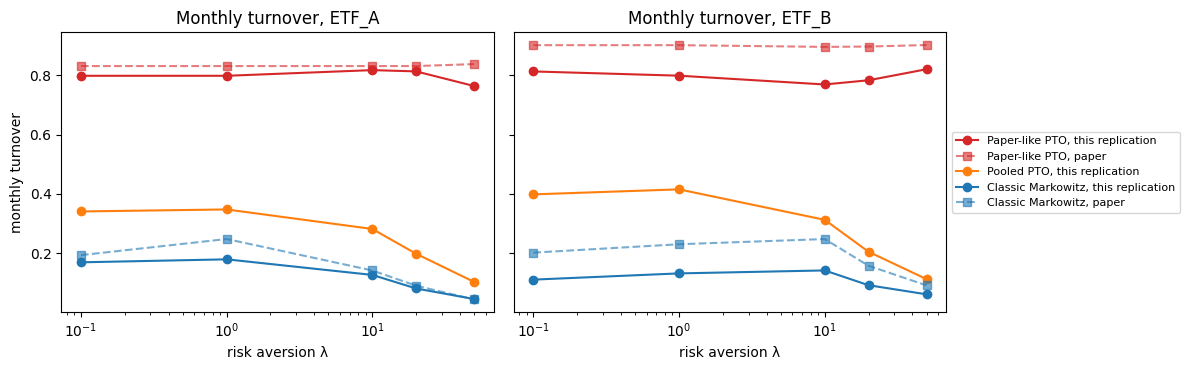

In [8]:
def summarize(rows):
    out = pd.DataFrame([backtest.metrics(g).rename(k) for k, g in rows.groupby(["strategy", "universe", "lam"])])
    out.index.names = ["strategy", "universe", "lam"]
    return out

full = summarize(rep_months)
first70 = summarize(rep_months[rep_months["month"] <= config.PAPER_LAST_MONTH])
metric_names = ["ann_return", "ann_vol", "sharpe", "max_drawdown", "turnover"]
paper = pd.concat([backtest.paper_rows("PTO").assign(strategy="Paper-like PTO"),
                   backtest.paper_rows("MVO").assign(strategy="Classic Markowitz")]).set_index(["strategy", "universe", "lam"])
side = lambda t: t[metric_names + ["effective_n"]].join(paper.add_prefix("paper_"))
comparison70 = side(first70)
cols = ["turnover", "paper_turnover", "ann_vol", "paper_ann_vol", "sharpe", "paper_sharpe",
        "max_drawdown", "paper_max_drawdown", "effective_n"]
print("First 70 months")
print(comparison70[cols].round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, u in zip(axes, universes):
    for name, color in (("Paper-like PTO", "tab:red"), ("Pooled PTO", "tab:orange"), ("Classic Markowitz", "tab:blue")):
        s = comparison70.loc[(name, u)]
        ax.plot(s.index, s["turnover"], "o-", color=color, label=f"{name}, this replication")
        if name != "Pooled PTO":
            ax.plot(s.index, s["paper_turnover"], "s--", color=color, alpha=0.6, label=f"{name}, paper")
    ax.set_xscale("log")
    ax.set_xlabel("risk aversion λ")
    ax.set_title(f"Monthly turnover, {u}")
axes[0].set_ylabel("monthly turnover")
axes[1].legend(fontsize=8, loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()

## 8. Pass criteria

The four criteria from the Replication Spec, on ETF_A over the first 70 months, with paper-like PTO as plain PTO:

1. Plain PTO turnover is at least 0.6 at every λ, and changes by less than 0.1 between λ = 0.1 and λ = 50.
2. Plain PTO turnover is at least three times classic Markowitz turnover at every λ from 10 up.
3. Classic Markowitz volatility falls at each step of the λ grid, and its turnover is below 0.3 at every λ.
4. Classic Markowitz volatility at λ = 10, 20 and 50 is within 30% of the paper's value.

Criteria 1 and 2 are H1. The same criteria are shown for ETF_B as a check; only ETF_A decides.

In [9]:
def criteria_for(u):
    pto = comparison70.loc[("Paper-like PTO", u)].sort_index()
    mvo = comparison70.loc[("Classic Markowitz", u)].sort_index()
    hi = [l for l in config.LAMBDA_GRID if l >= 10]
    ratio = pto.loc[hi, "turnover"] / mvo.loc[hi, "turnover"]
    gap = (mvo.loc[hi, "ann_vol"] / mvo.loc[hi, "paper_ann_vol"] - 1).abs()
    change = abs(pto.loc[50.0, "turnover"] - pto.loc[0.1, "turnover"])
    return pd.DataFrame([
        {"universe": u, "check": "1. PTO trades heavily at every λ",
         "status": "PASS" if (pto["turnover"] >= 0.6).all() and change < 0.1 else "FAIL",
         "detail": f"turnover {pto['turnover'].min():.3f} to {pto['turnover'].max():.3f}; change {change:.3f}"},
        {"universe": u, "check": "2. PTO trades 3x Markowitz at λ ≥ 10",
         "status": "PASS" if (ratio >= 3).all() else "FAIL",
         "detail": "ratios " + ", ".join(f"{r:.1f}" for r in ratio)},
        {"universe": u, "check": "3. Markowitz volatility falls, turnover < 0.3",
         "status": "PASS" if (mvo["ann_vol"].diff().dropna() < 0).all() and (mvo["turnover"] < 0.3).all() else "FAIL",
         "detail": "volatility " + ", ".join(f"{v:.3f}" for v in mvo["ann_vol"])},
        {"universe": u, "check": "4. Markowitz volatility within 30% of paper",
         "status": "PASS" if (gap <= 0.3).all() else "FAIL",
         "detail": "gaps " + ", ".join(f"{g:.0%}" for g in gap) + " at λ = 10, 20, 50"},
    ])

criteria = pd.concat([criteria_for(u) for u in universes], ignore_index=True)
print(criteria.to_string(index=False))
a = criteria[criteria["universe"] == "ETF_A"]
checks.append(a.drop(columns="universe").assign(table="Pass criteria (ETF_A)"))
print()
print("Replication on ETF_A:", "all four criteria pass." if (a["status"] == "PASS").all()
      else "not all criteria pass: " + ", ".join(a.loc[a["status"] == "FAIL", "check"]))

universe                                         check status                                       detail
   ETF_A              1. PTO trades heavily at every λ   PASS        turnover 0.764 to 0.817; change 0.035
   ETF_A          2. PTO trades 3x Markowitz at λ ≥ 10   PASS                       ratios 6.4, 10.0, 16.7
   ETF_A 3. Markowitz volatility falls, turnover < 0.3   PASS volatility 0.196, 0.178, 0.097, 0.072, 0.061
   ETF_A   4. Markowitz volatility within 30% of paper   PASS           gaps 10%, 8%, 7% at λ = 10, 20, 50
   ETF_B              1. PTO trades heavily at every λ   PASS        turnover 0.769 to 0.820; change 0.007
   ETF_B          2. PTO trades 3x Markowitz at λ ≥ 10   PASS                        ratios 5.4, 8.5, 13.3
   ETF_B 3. Markowitz volatility falls, turnover < 0.3   PASS volatility 0.239, 0.235, 0.159, 0.143, 0.138
   ETF_B   4. Markowitz volatility within 30% of paper   PASS         gaps 11%, 13%, 14% at λ = 10, 20, 50

Replication on ETF_A: all four crite

## 9. What the portfolios hold

Target weights on ETF_A at λ = 20. The paper's PTO behaves like a single ETF switched almost every month. The table gives the share of months in which one ETF holds more than 90% of the portfolio.

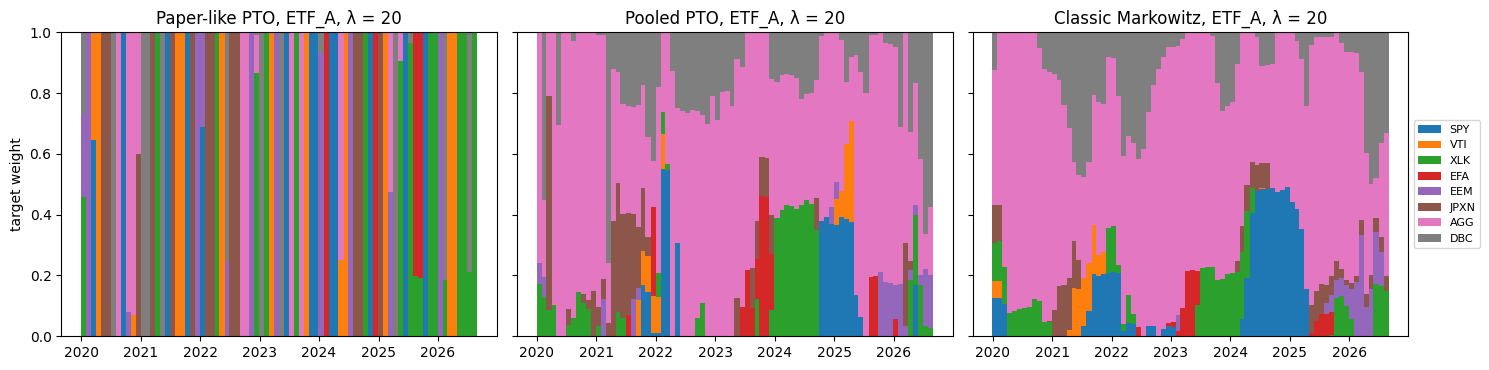

lam                         0.1   1.0   10.0  20.0  50.0
strategy          universe                              
Classic Markowitz ETF_A     0.99  0.61  0.00  0.10  0.17
                  ETF_B     0.83  0.60  0.00  0.00  0.00
Paper-like PTO    ETF_A     1.00  1.00  0.89  0.86  0.57
                  ETF_B     1.00  1.00  0.91  0.86  0.69
Pooled PTO        ETF_A     0.99  0.84  0.03  0.04  0.07
                  ETF_B     1.00  0.63  0.06  0.03  0.03


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
colors = plt.cm.tab10(np.arange(len(config.ETF_A)))
for ax, name in zip(axes, ("Paper-like PTO", "Pooled PTO", "Classic Markowitz")):
    w = weights_by_run[(name, "ETF_A", 20.0)].pivot(index="date", columns="ticker", values="target")[config.ETF_A]
    ax.stackplot(w.index, w.T.to_numpy(), labels=config.ETF_A, colors=colors, step="post")
    ax.set_title(f"{name}, ETF_A, λ = 20")
    ax.set_ylim(0, 1)
axes[0].set_ylabel("target weight")
axes[2].legend(loc="center left", bbox_to_anchor=(1, 0.5), fontsize=8)
plt.tight_layout()
plt.show()

last = pd.Timestamp(config.PAPER_LAST_MONTH) - pd.offsets.MonthEnd(1)
single = pd.DataFrame([{"strategy": n, "universe": u, "lam": l,
                        "share": (w.groupby("date")["target"].max().loc[:last] > 0.9).mean()}
                       for (n, u, l), w in weights_by_run.items()])
print(single.pivot_table(index=["strategy", "universe"], columns="lam", values="share").round(2).to_string())

## 10. Save

Saves under separate names, so Notebook 4's own outputs are kept.

In [11]:
fc_paper.to_parquet(proc / "Paper-like PTO Forecasts.parquet", index=False)
rep_months.to_parquet(proc / "Replication Months (paper-like).parquet", index=False)
results = pd.concat([side(full).assign(window="81 months"), comparison70.assign(window="70 months")])
results.reset_index().to_csv(DIRS["reports"] / "Replication Results (paper-like).csv", index=False)
all_checks = pd.concat(checks, ignore_index=True)
all_checks.to_csv(DIRS["reports"] / "Replication Checks (paper-like).csv", index=False)
print("Saved: Paper-like PTO Forecasts, Replication Months (paper-like), Replication Results (paper-like),\n"
      "       Replication Checks (paper-like)")

Saved: Paper-like PTO Forecasts, Replication Months (paper-like), Replication Results (paper-like),
       Replication Checks (paper-like)


## 11. Summary

Key figures for the process log. After the run, push the notebook with its outputs to GitHub.

In [12]:
a = comparison70.xs("ETF_A", level="universe")
print(f"ETF_A, 70 months, paper-like PTO turnover:   {a.loc['Paper-like PTO', 'turnover'].min():.2f} to {a.loc['Paper-like PTO', 'turnover'].max():.2f} (paper 0.83 to 0.84)")
print(f"ETF_A, 70 months, pooled PTO turnover:       {a.loc['Pooled PTO', 'turnover'].min():.2f} to {a.loc['Pooled PTO', 'turnover'].max():.2f}")
print(f"ETF_A, 70 months, classic Markowitz turnover: {a.loc['Classic Markowitz', 'turnover'].min():.2f} to {a.loc['Classic Markowitz', 'turnover'].max():.2f} (paper 0.05 to 0.25)")
print(f"Pass criteria (ETF_A): {', '.join(criteria.loc[criteria['universe'] == 'ETF_A', 'status'])}")
print(f"Checks: {(all_checks['status'] == 'PASS').sum()} passed, {(all_checks['status'] == 'FAIL').sum()} failed")

ETF_A, 70 months, paper-like PTO turnover:   0.76 to 0.82 (paper 0.83 to 0.84)
ETF_A, 70 months, pooled PTO turnover:       0.10 to 0.35
ETF_A, 70 months, classic Markowitz turnover: 0.05 to 0.18 (paper 0.05 to 0.25)
Pass criteria (ETF_A): PASS, PASS, PASS, PASS
Checks: 170 passed, 0 failed
